<a href="https://colab.research.google.com/github/lizlorenzana931109-art/FinPredict-Actividad5/blob/main/fuentes/02_preparacion_datos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# FinPredict | Actividad 5
## 02. Preparación, calidad y protección de datos

### Objetivo

Desarrollar un proceso reproducible de preparación del dataset sintético FinPredict para su posterior utilización en modelos supervisados de predicción de incumplimiento hipotecario.

### Fuente de información

El proceso utiliza `finpredict_fuente_calidad.parquet`, generado en el notebook `01_construccion_dataset.ipynb`.

La fuente contiene:

- 390,861 registros iniciales.
- 33 columnas.
- Información financiera y contractual sintética.
- Atributos personales ficticios.
- 1,100 incidencias de calidad introducidas deliberadamente.

### Alcance del procesamiento

1. Carga y verificación de integridad de la fuente.
2. Diagnóstico inicial de calidad.
3. Deduplicación por contrato y fecha de corte.
4. Estandarización de fechas y variables categóricas.
5. Tratamiento de valores faltantes y montos inválidos.
6. Protección y minimización de datos personales.
7. Visualización y evaluación de calidad antes y después.
8. Versionamiento y generación del dataset preparado.

### Principios metodológicos

- Preservar intacta la fuente inicial.
- Documentar cada transformación y su justificación.
- Evitar fuga de información temporal.
- Mantener separada la ventana de evaluación final.
- Diferenciar incidencias sintéticas controladas de defectos observados en datos reales.
- Conservar la trazabilidad del proceso para fines de auditoría y reproducibilidad.

**Proyecto:** FinPredict  
**Etapa:** Fase 1 — Calidad y preparación de datos  
**Herramientas:** Python, pandas, NumPy y Google Colab


In [10]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 2
# Carga y verificación de la fuente inicial
# ============================================================

import pandas as pd
import numpy as np
import hashlib
import json
import requests
from io import BytesIO

# Repositorio GitHub
BASE_URL = (
    "https://raw.githubusercontent.com/"
    "lizlorenzana931109-art/"
    "FinPredict-Actividad5/main/datos/datos_ini/"
)

URL_FUENTE = BASE_URL + "finpredict_fuente_calidad.parquet"
URL_MANIFIESTO = BASE_URL + "manifiesto_incidencias.json"

# Descargar manifiesto
respuesta_manifiesto = requests.get(
    URL_MANIFIESTO, timeout=60
)
respuesta_manifiesto.raise_for_status()

manifiesto = respuesta_manifiesto.json()

# Descargar Parquet
respuesta_fuente = requests.get(
    URL_FUENTE, timeout=180
)
respuesta_fuente.raise_for_status()

contenido = respuesta_fuente.content

# Verificar huella de integridad
sha256_calculado = hashlib.sha256(contenido).hexdigest()

assert sha256_calculado == manifiesto["sha256"], (
    "La huella SHA-256 no coincide con el manifiesto."
)

# Leer sin modificar la fuente
df_original = pd.read_parquet(BytesIO(contenido))

# Verificaciones estructurales
assert len(df_original) == 390_861
assert df_original.shape[1] == 33

assert len(df_original) == manifiesto["observaciones"]
assert df_original.shape[1] == manifiesto["columnas"]

print("FINPREDICT | Carga de fuente inicial")
print("-" * 60)

print(f"Observaciones: {len(df_original):,}")
print(f"Columnas: {df_original.shape[1]}")
print(f"SHA-256 verificado: {sha256_calculado[:16]}...")
print("Fuente original preservada sin modificaciones.")

print("-" * 60)

display(df_original.head())


FINPREDICT | Carga de fuente inicial
------------------------------------------------------------
Observaciones: 390,861
Columnas: 33
SHA-256 verificado: b84e037458d6e794...
Fuente original preservada sin modificaciones.
------------------------------------------------------------


,id_credito,id_ventana,fecha_corte,inicio_prediccion,fin_prediccion,uso,fecha_apertura,incumplimiento_90d,monto_original,plazo_meses,...,mora_90_corte,tipo_empleo,edad,region,pagos_parciales_3m,regularizaciones_3m,categoria_cobertura_3m,nombre_titular,rfc_sintetico,direccion
0,HIP000056,2,2021-06-30,2021-07-01,2021-09-30,HISTORICO,2021-03-21,0,4722743.85,240,...,0,ASALARIADO,61,CENTRO,0.0,0.0,COBERTURA_CERCANA_100,DANIELA CASTILLO MARTINEZ,CAMD910719NG2,"CALLE ENCINOS 947, COL. VILLAS DEL BOSQUE, C.P..."
1,HIP000104,2,2021-06-30,2021-07-01,2021-09-30,HISTORICO,2021-01-14,1,1326400.32,180,...,0,ASALARIADO,42,SUR,1.0,0.0,COBERTURA_BAJA,DANIELA ROMERO HERNANDEZ,ROHD900419AI7,"AVENIDA JACARANDAS 875, COL. LAS FLORES, C.P. ..."
2,HIP000117,2,2021-06-30,2021-07-01,2021-09-30,HISTORICO,2021-03-10,0,1974095.99,240,...,0,ASALARIADO,58,CENTRO,0.0,0.0,COBERTURA_CERCANA_100,ELENA LOPEZ LOPEZ,LOLE9105081RY,"AVENIDA CENTRAL 194, COL. VILLAS DEL BOSQUE, C..."
3,HIP000138,2,2021-06-30,2021-07-01,2021-09-30,HISTORICO,2021-02-26,0,3820423.14,240,...,0,ASALARIADO,60,OCCIDENTE,0.0,1.0,COBERTURA_BAJA,CARLOS HERNANDEZ GARCIA,HEGC960417IRI,"AVENIDA CENTRAL 981, COL. JARDINES DEL VALLE, ..."
4,HIP000147,2,2021-06-30,2021-07-01,2021-09-30,HISTORICO,2021-03-05,0,1247588.90,180,...,0,INDEPENDIENTE,54,NORTE,0.0,0.0,COBERTURA_CERCANA_100,PAULA PEREZ MORALES,PEMP8709033TK,"CALLE LAS ROSAS 408, COL. LAS FLORES, C.P. 79623"


In [11]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 3
# Diagnóstico inicial de calidad de datos
# ============================================================

import pandas as pd
import numpy as np

# No modificar la fuente original
df_diagnostico = df_original.copy()

# Detectar inconsistencias de formato en tipo_empleo
empleo = df_diagnostico["tipo_empleo"].astype("string")

formatos_empleo = int(
    empleo.ne(empleo.str.strip().str.upper()).sum()
)

# Detectar fechas en formato DD/MM/YYYY
fechas_alternativas = int(
    df_diagnostico["fecha_apertura"]
    .astype("string")
    .str.fullmatch(r"\d{2}/\d{2}/\d{4}")
    .sum()
)

# Identificar duplicados
duplicados_exactos = int(
    df_diagnostico.duplicated().sum()
)

duplicados_clave = int(
    df_diagnostico.duplicated(
        ["id_credito", "fecha_corte"]
    ).sum()
)

# Detectar importes inválidos
montos_invalidos = int(
    (df_diagnostico["monto_original"] <= 0).sum()
)

# Evaluar completitud
nulos_ingreso = int(
    df_diagnostico["ingreso_mensual"].isna().sum()
)

# Identificadores personales presentes
columnas_personales = [
    "nombre_titular",
    "rfc_sintetico",
    "direccion"
]

registros_identificados = int(
    df_diagnostico[columnas_personales]
    .notna().all(axis=1).sum()
)

# Consolidar diagnóstico
resumen_diagnostico = pd.DataFrame({
    "control": [
        "Registros totales",
        "Ingresos faltantes",
        "Formatos de empleo inconsistentes",
        "Montos contractuales inválidos",
        "Fechas con formato alternativo",
        "Duplicados exactos",
        "Duplicados por clave",
        "Registros con identificación personal"
    ],
    "resultado": [
        len(df_diagnostico),
        nulos_ingreso,
        formatos_empleo,
        montos_invalidos,
        fechas_alternativas,
        duplicados_exactos,
        duplicados_clave,
        registros_identificados
    ]
})

print("FINPREDICT | Diagnóstico inicial de calidad")
print("-" * 65)

display(resumen_diagnostico)

print("\nValores nulos por variable:")
display(
    df_diagnostico.isna().sum()
    .loc[lambda x: x > 0]
    .to_frame("nulos")
)

print("-" * 65)
print("Diagnóstico completado. Fuente inicial sin modificaciones.")


FINPREDICT | Diagnóstico inicial de calidad
-----------------------------------------------------------------


,control,resultado
0,Registros totales,390861
1,Ingresos faltantes,300
2,Formatos de empleo inconsistentes,250
3,Montos contractuales inválidos,100
4,Fechas con formato alternativo,250
5,Duplicados exactos,200
6,Duplicados por clave,200
7,Registros con identificación personal,390861



Valores nulos por variable:


,nulos
ingreso_mensual,300


-----------------------------------------------------------------
Diagnóstico completado. Fuente inicial sin modificaciones.


In [12]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 4
# Deduplicación controlada de registros
# ============================================================

import pandas as pd

# Crear copia de trabajo sin modificar la fuente original
df_limpio = df_original.copy(deep=True)

CLAVE_NEGOCIO = ["id_credito", "fecha_corte"]

# Identificar registros duplicados
duplicados_exactos = int(
    df_limpio.duplicated(keep="first").sum()
)

duplicados_clave = int(
    df_limpio.duplicated(
        subset=CLAVE_NEGOCIO,
        keep="first"
    ).sum()
)

# Control de conflictos
assert duplicados_exactos == duplicados_clave, (
    "Existen registros con la misma clave, "
    "pero con diferencias en sus atributos."
)

registros_antes = len(df_limpio)

# Eliminar exclusivamente duplicados exactos
df_limpio = (
    df_limpio
    .drop_duplicates(keep="first")
    .reset_index(drop=True)
)

registros_despues = len(df_limpio)

# Resumen de auditoría
resumen_deduplicacion = pd.DataFrame({
    "indicador": [
        "Registros antes",
        "Duplicados identificados",
        "Registros eliminados",
        "Registros después",
        "Duplicados restantes"
    ],
    "resultado": [
        registros_antes,
        duplicados_exactos,
        registros_antes - registros_despues,
        registros_despues,
        int(df_limpio.duplicated().sum())
    ]
})

# Validaciones
assert duplicados_exactos == 200
assert registros_despues == 390_661

assert not df_limpio.duplicated(
    subset=CLAVE_NEGOCIO
).any()

print("FINPREDICT | Deduplicación")
print("-" * 60)

display(resumen_deduplicacion)

print("-" * 60)
print("Deduplicación validada. Fuente original preservada.")


FINPREDICT | Deduplicación
------------------------------------------------------------


,indicador,resultado
0,Registros antes,390861
1,Duplicados identificados,200
2,Registros eliminados,200
3,Registros después,390661
4,Duplicados restantes,0


------------------------------------------------------------
Deduplicación validada. Fuente original preservada.


In [13]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 5
# Estandarización de fechas de apertura
# ============================================================

import pandas as pd

# Conservar los valores originales para auditoría
fechas_originales = df_limpio["fecha_apertura"].copy()

# Identificar los dos formatos
formato_iso = fechas_originales.str.fullmatch(
    r"\d{4}-\d{2}-\d{2}"
)

formato_alterno = fechas_originales.str.fullmatch(
    r"\d{2}/\d{2}/\d{4}"
)

# Validar que todos los registros tengan un formato conocido
assert (formato_iso | formato_alterno).all(), (
    "Se encontraron fechas con un formato no reconocido."
)

# Convertir cada formato explícitamente
fechas_convertidas = pd.Series(
    pd.NaT,
    index=df_limpio.index,
    dtype="datetime64[ns]"
)

fechas_convertidas.loc[formato_iso] = pd.to_datetime(
    fechas_originales.loc[formato_iso],
    format="%Y-%m-%d",
    errors="raise"
)

fechas_convertidas.loc[formato_alterno] = pd.to_datetime(
    fechas_originales.loc[formato_alterno],
    format="%d/%m/%Y",
    errors="raise"
)

# Aplicar la estandarización
df_limpio["fecha_apertura"] = fechas_convertidas

# Validaciones temporales
assert df_limpio["fecha_apertura"].notna().all()

assert (
    df_limpio["fecha_apertura"] <= df_limpio["fecha_corte"]
).all()

assert (
    df_limpio["fecha_apertura"].dtype
    == "datetime64[ns]"
)

# Resumen
resumen_fechas = pd.DataFrame({
    "indicador": [
        "Fechas evaluadas",
        "Fechas formato ISO",
        "Fechas formato alternativo",
        "Fechas convertidas",
        "Fechas inválidas restantes"
    ],
    "resultado": [
        len(df_limpio),
        int(formato_iso.sum()),
        int(formato_alterno.sum()),
        len(df_limpio),
        int(df_limpio["fecha_apertura"].isna().sum())
    ]
})

print("FINPREDICT | Estandarización temporal")
print("-" * 60)

display(resumen_fechas)

print("\nTipo de dato resultante:")
print(df_limpio["fecha_apertura"].dtype)

print("-" * 60)
print("Fechas estandarizadas sin alterar su valor cronológico.")


FINPREDICT | Estandarización temporal
------------------------------------------------------------


,indicador,resultado
0,Fechas evaluadas,390661
1,Fechas formato ISO,390411
2,Fechas formato alternativo,250
3,Fechas convertidas,390661
4,Fechas inválidas restantes,0



Tipo de dato resultante:
datetime64[ns]
------------------------------------------------------------
Fechas estandarizadas sin alterar su valor cronológico.


In [14]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 6
# Estandarización de tipo de empleo
# ============================================================

import pandas as pd

# 1. Conservar valores previos para auditoría
empleo_original = df_limpio["tipo_empleo"].copy()

# 2. Normalización de categorías
empleo_normalizado = (
    empleo_original
    .astype("string")
    .str.strip()
    .str.upper()
)

# 3. Identificar registros corregidos
mascara_correccion = (
    empleo_original.astype("string") != empleo_normalizado
)

registros_corregidos = int(mascara_correccion.sum())

# 4. Aplicar estandarización
df_limpio["tipo_empleo"] = empleo_normalizado

# 5. Validar catálogo permitido
CATEGORIAS_EMPLEO = {
    "ASALARIADO",
    "INDEPENDIENTE",
    "EMPRESARIO"
}

categorias_observadas = set(
    df_limpio["tipo_empleo"].dropna().unique()
)

assert categorias_observadas == CATEGORIAS_EMPLEO

assert registros_corregidos == 250

assert df_limpio["tipo_empleo"].notna().all()

assert (
    df_limpio["tipo_empleo"]
    == df_limpio["tipo_empleo"].str.strip().str.upper()
).all()

# 6. Resumen
resumen_empleo = pd.DataFrame({
    "indicador": [
        "Registros evaluados",
        "Formatos corregidos",
        "Categorías válidas",
        "Inconsistencias restantes"
    ],
    "resultado": [
        len(df_limpio),
        registros_corregidos,
        len(categorias_observadas),
        0
    ]
})

print("FINPREDICT | Estandarización de empleo")
print("-" * 60)

display(resumen_empleo)

print("\nDistribución de categorías:")
display(
    df_limpio["tipo_empleo"]
    .value_counts()
    .rename_axis("tipo_empleo")
    .reset_index(name="observaciones")
)

print("-" * 60)
print("Estandarización de categorías satisfactoria.")


FINPREDICT | Estandarización de empleo
------------------------------------------------------------


,indicador,resultado
0,Registros evaluados,390661
1,Formatos corregidos,250
2,Categorías válidas,3
3,Inconsistencias restantes,0



Distribución de categorías:


,tipo_empleo,observaciones
0,ASALARIADO,255177
1,INDEPENDIENTE,98703
2,EMPRESARIO,36781


------------------------------------------------------------
Estandarización de categorías satisfactoria.


In [15]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 7
# Diagnóstico de ingresos faltantes por contrato
# ============================================================

import pandas as pd

# Contratos con ingresos faltantes
df_ingresos_nulos = df_limpio.loc[
    df_limpio["ingreso_mensual"].isna(),
    ["id_credito", "fecha_corte"]
].copy()

# Fuentes disponibles hasta cada fecha de corte
df_ingresos_validos = df_limpio.loc[
    df_limpio["ingreso_mensual"].notna(),
    ["id_credito", "fecha_corte", "ingreso_mensual"]
].copy()

# Identificar contratos con un ingreso consistente
consistencia = (
    df_ingresos_validos.groupby("id_credito")
    .agg(
        ingresos_distintos=("ingreso_mensual", "nunique"),
        ingreso_referencia=("ingreso_mensual", "first")
    )
)

# Buscar último ingreso válido observado hasta el corte
referencias = pd.merge_asof(
    df_ingresos_nulos.sort_values(["fecha_corte", "id_credito"]),
    df_ingresos_validos.sort_values(["fecha_corte", "id_credito"]),
    on="fecha_corte",
    by="id_credito",
    direction="backward"
)

referencias = referencias.merge(
    consistencia[["ingresos_distintos"]],
    left_on="id_credito",
    right_index=True,
    how="left"
)

referencias["recuperable"] = (
    referencias["ingreso_mensual"].notna()
    & referencias["ingresos_distintos"].eq(1)
)

# Resumen
resumen_recuperacion = pd.DataFrame({
    "indicador": [
        "Ingresos faltantes",
        "Contratos afectados",
        "Recuperables desde historial previo",
        "Sin referencia histórica previa",
        "Contratos con ingreso inconsistente"
    ],
    "resultado": [
        len(referencias),
        referencias["id_credito"].nunique(),
        int(referencias["recuperable"].sum()),
        int(referencias["ingreso_mensual"].isna().sum()),
        int(referencias["ingresos_distintos"].gt(1).sum())
    ]
})

print("FINPREDICT | Diagnóstico de ingresos faltantes")
print("-" * 60)

display(resumen_recuperacion)

print("-" * 60)
print("Diagnóstico completado. Sin imputaciones aplicadas.")


FINPREDICT | Diagnóstico de ingresos faltantes
------------------------------------------------------------


,indicador,resultado
0,Ingresos faltantes,300
1,Contratos afectados,297
2,Recuperables desde historial previo,259
3,Sin referencia histórica previa,41
4,Contratos con ingreso inconsistente,0


------------------------------------------------------------
Diagnóstico completado. Sin imputaciones aplicadas.


In [16]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 8
# Recuperación histórica de ingresos faltantes
# ============================================================

import numpy as np
import pandas as pd

# Guardar trazabilidad del problema original
df_limpio["ingreso_faltante_original"] = (
    df_limpio["ingreso_mensual"].isna().astype(int)
)

df_limpio["metodo_recuperacion_ingreso"] = "ORIGINAL"

# Seleccionar únicamente referencias históricas válidas
referencias_validas = referencias.loc[
    referencias["recuperable"],
    ["id_credito", "fecha_corte", "ingreso_mensual"]
].copy()

# Renombrar para evitar confusiones
referencias_validas = referencias_validas.rename(
    columns={"ingreso_mensual": "ingreso_recuperado"}
)

# Integrar referencias a la tabla de trabajo
df_limpio = df_limpio.merge(
    referencias_validas,
    on=["id_credito", "fecha_corte"],
    how="left",
    validate="one_to_one"
)

# Aplicar únicamente las recuperaciones justificadas
mascara_recuperacion = (
    df_limpio["ingreso_mensual"].isna()
    & df_limpio["ingreso_recuperado"].notna()
)

recuperados = int(mascara_recuperacion.sum())

df_limpio.loc[
    mascara_recuperacion, "ingreso_mensual"
] = df_limpio.loc[
    mascara_recuperacion, "ingreso_recuperado"
]

df_limpio.loc[
    mascara_recuperacion, "metodo_recuperacion_ingreso"
] = "HISTORICO_PREVIO"

# Retirar columna auxiliar de cruce
df_limpio = df_limpio.drop(columns="ingreso_recuperado")

# Comprobar que los ingresos recuperados sean positivos
assert (
    df_limpio.loc[
        mascara_recuperacion, "ingreso_mensual"
    ] > 0
).all()

assert recuperados == 259
assert df_limpio["ingreso_mensual"].isna().sum() == 41

# Resumen
resumen_recuperacion_ingresos = pd.DataFrame({
    "indicador": [
        "Valores faltantes iniciales",
        "Recuperados desde historial anterior",
        "Pendientes de tratamiento",
        "Valores originales modificados"
    ],
    "resultado": [
        300,
        recuperados,
        int(df_limpio["ingreso_mensual"].isna().sum()),
        0
    ]
})

print("FINPREDICT | Recuperación histórica de ingresos")
print("-" * 60)

display(resumen_recuperacion_ingresos)

print("-" * 60)
print("Recuperación histórica completada.")


FINPREDICT | Recuperación histórica de ingresos
------------------------------------------------------------


,indicador,resultado
0,Valores faltantes iniciales,300
1,Recuperados desde historial anterior,259
2,Pendientes de tratamiento,41
3,Valores originales modificados,0


------------------------------------------------------------
Recuperación histórica completada.


In [17]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 9
# Imputación estadística de ingresos faltantes
# ============================================================

import pandas as pd

# Verificar que la recuperación histórica terminó
nulos_antes = int(df_limpio["ingreso_mensual"].isna().sum())

assert nulos_antes == 41, (
    f"Se esperaban 41 ingresos faltantes y hay {nulos_antes}."
)

# Identificar observaciones pendientes
mascara_pendientes = df_limpio["ingreso_mensual"].isna()

# Medianas calculadas solo con registros históricos
df_referencia = df_limpio.loc[
    (df_limpio["uso"] == "HISTORICO")
    & df_limpio["ingreso_mensual"].notna()
]

medianas_empleo = (
    df_referencia
    .groupby("tipo_empleo")["ingreso_mensual"]
    .median()
)

# Valor de respaldo para una categoría sin referencia
mediana_general = df_referencia["ingreso_mensual"].median()

# Estimar exclusivamente los ingresos pendientes
valores_estimados = (
    df_limpio.loc[mascara_pendientes, "tipo_empleo"]
    .map(medianas_empleo)
    .fillna(mediana_general)
)

df_limpio.loc[
    mascara_pendientes, "ingreso_mensual"
] = valores_estimados.to_numpy()

df_limpio.loc[
    mascara_pendientes, "metodo_recuperacion_ingreso"
] = "MEDIANA_TIPO_EMPLEO"

# Validaciones
nulos_despues = int(df_limpio["ingreso_mensual"].isna().sum())

assert nulos_despues == 0
assert (df_limpio["ingreso_mensual"] > 0).all()

assert (
    df_limpio["metodo_recuperacion_ingreso"]
    .eq("MEDIANA_TIPO_EMPLEO")
    .sum()
) == 41

# Reporte de tratamientos
resumen_imputacion = (
    df_limpio["metodo_recuperacion_ingreso"]
    .value_counts()
    .rename_axis("metodo")
    .reset_index(name="registros")
)

print("FINPREDICT | Imputación de ingresos")
print("-" * 60)

print("Medianas por tipo de empleo:")
display(medianas_empleo.to_frame("mediana_ingreso"))

print("\nTratamientos aplicados:")
display(resumen_imputacion)

print(f"\nValores faltantes antes: {nulos_antes}")
print(f"Valores faltantes después: {nulos_despues}")

print("-" * 60)
print("Tratamiento de ingresos completado.")


FINPREDICT | Imputación de ingresos
------------------------------------------------------------
Medianas por tipo de empleo:


,mediana_ingreso
tipo_empleo,
ASALARIADO,85499.27
EMPRESARIO,87317.02
INDEPENDIENTE,86695.83



Tratamientos aplicados:


,metodo,registros
0,ORIGINAL,390361
1,HISTORICO_PREVIO,259
2,MEDIANA_TIPO_EMPLEO,41



Valores faltantes antes: 41
Valores faltantes después: 0
------------------------------------------------------------
Tratamiento de ingresos completado.


In [18]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 10
# Consistencia de variables financieras derivadas
# ============================================================

import numpy as np
import pandas as pd

# Identificar registros cuyo ingreso fue tratado
mascara_tratados = df_limpio[
    "metodo_recuperacion_ingreso"
].isin([
    "HISTORICO_PREVIO",
    "MEDIANA_TIPO_EMPLEO"
])

# Conservar valores previos para auditoría
relacion_anterior = df_limpio[
    "relacion_pago_ingreso"
].copy()

# Calcular relación a partir de los valores actuales
relacion_calculada = (
    df_limpio["pago_mensual"]
    / df_limpio["ingreso_mensual"]
)

# Identificar diferencias con tolerancia numérica
diferencias = ~np.isclose(
    relacion_anterior,
    relacion_calculada,
    rtol=1e-5,
    atol=1e-8,
    equal_nan=True
)

# Diagnóstico previo
diferencias_tratados = int(
    (diferencias & mascara_tratados).sum()
)

diferencias_no_tratados = int(
    (diferencias & ~mascara_tratados).sum()
)

# Control: no modificar inconsistencias ajenas
# al tratamiento de ingresos sin investigarlas
assert diferencias_no_tratados == 0, (
    "Se detectaron diferencias en registros "
    "sin tratamiento de ingresos. Revisar antes "
    "de continuar."
)

# Recalcular solamente registros tratados
df_limpio.loc[
    mascara_tratados, "relacion_pago_ingreso"
] = relacion_calculada.loc[mascara_tratados]

# Validar consistencia global
diferencias_restantes = int((
    ~np.isclose(
        df_limpio["relacion_pago_ingreso"],
        relacion_calculada,
        rtol=1e-5,
        atol=1e-8,
        equal_nan=True
    )
).sum())

assert diferencias_restantes == 0

# Resumen de auditoría
resumen_consistencia = pd.DataFrame({
    "indicador": [
        "Registros con ingreso tratado",
        "Relaciones inconsistentes detectadas",
        "Inconsistencias ajenas al tratamiento",
        "Inconsistencias restantes"
    ],
    "resultado": [
        int(mascara_tratados.sum()),
        diferencias_tratados,
        diferencias_no_tratados,
        diferencias_restantes
    ]
})

print("FINPREDICT | Conciliación financiera")
print("-" * 60)

display(resumen_consistencia)

print("-" * 60)
print("Relación pago-ingreso validada.")


FINPREDICT | Conciliación financiera
------------------------------------------------------------


,indicador,resultado
0,Registros con ingreso tratado,300
1,Relaciones inconsistentes detectadas,41
2,Inconsistencias ajenas al tratamiento,0
3,Inconsistencias restantes,0


------------------------------------------------------------
Relación pago-ingreso validada.


In [19]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 11
# Diagnóstico de montos contractuales inválidos
# ============================================================

import pandas as pd

# Identificar los montos inválidos
mascara_montos_invalidos = (
    df_limpio["monto_original"].isna()
    | (df_limpio["monto_original"] <= 0)
)

df_montos_invalidos = df_limpio.loc[
    mascara_montos_invalidos,
    ["id_credito", "fecha_corte", "monto_original", "uso"]
].copy()

# Referencias válidas de cada contrato
df_montos_validos = df_limpio.loc[
    df_limpio["monto_original"].gt(0),
    ["id_credito", "fecha_corte", "monto_original"]
].copy()

# Verificar consistencia de los montos contractuales
consistencia_montos = (
    df_montos_validos.groupby("id_credito")
    .agg(
        montos_distintos=("monto_original", "nunique")
    )
)

# Recuperar última referencia observada hasta el corte
referencias_montos = pd.merge_asof(
    df_montos_invalidos.sort_values(
        ["fecha_corte", "id_credito"]
    ),
    df_montos_validos.sort_values(
        ["fecha_corte", "id_credito"]
    ),
    on="fecha_corte",
    by="id_credito",
    direction="backward",
    suffixes=("_invalido", "_referencia")
)

referencias_montos = referencias_montos.merge(
    consistencia_montos,
    left_on="id_credito",
    right_index=True,
    how="left"
)

referencias_montos["recuperable"] = (
    referencias_montos["monto_original_referencia"].gt(0)
    & referencias_montos["montos_distintos"].eq(1)
)

resumen_montos = pd.DataFrame({
    "indicador": [
        "Montos inválidos detectados",
        "Contratos afectados",
        "Recuperables desde historial",
        "Sin referencia anterior válida",
        "Referencias contractuales inconsistentes"
    ],
    "resultado": [
        len(referencias_montos),
        referencias_montos["id_credito"].nunique(),
        int(referencias_montos["recuperable"].sum()),
        int(
            referencias_montos[
                "monto_original_referencia"
            ].isna().sum()
        ),
        int(
            referencias_montos["montos_distintos"].gt(1).sum()
        )
    ]
})

print("FINPREDICT | Diagnóstico de montos contractuales")
print("-" * 60)

display(resumen_montos)

print("-" * 60)
print("Diagnóstico completado. Sin modificar montos.")


FINPREDICT | Diagnóstico de montos contractuales
------------------------------------------------------------


,indicador,resultado
0,Montos inválidos detectados,100
1,Contratos afectados,100
2,Recuperables desde historial,91
3,Sin referencia anterior válida,9
4,Referencias contractuales inconsistentes,0


------------------------------------------------------------
Diagnóstico completado. Sin modificar montos.


In [20]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 12
# Recuperación de montos contractuales desde historial
# ============================================================

import pandas as pd

# Registrar la incidencia original
df_limpio["monto_invalido_original"] = (
    df_limpio["monto_original"].isna()
    | df_limpio["monto_original"].le(0)
).astype(int)

df_limpio["metodo_recuperacion_monto"] = "ORIGINAL"

# Seleccionar las referencias históricas válidas
montos_recuperables = referencias_montos.loc[
    referencias_montos["recuperable"],
    ["id_credito", "fecha_corte", "monto_original_referencia"]
].copy()

montos_recuperables = montos_recuperables.rename(
    columns={
        "monto_original_referencia": "monto_recuperado"
    }
)

# Integrar referencias sin modificar otros registros
df_limpio = df_limpio.merge(
    montos_recuperables,
    on=["id_credito", "fecha_corte"],
    how="left",
    validate="one_to_one"
)

# Recuperar únicamente los montos inválidos
mascara_recuperacion = (
    df_limpio["monto_invalido_original"].eq(1)
    & df_limpio["monto_recuperado"].gt(0)
)

recuperados = int(mascara_recuperacion.sum())

df_limpio.loc[
    mascara_recuperacion, "monto_original"
] = df_limpio.loc[
    mascara_recuperacion, "monto_recuperado"
]

df_limpio.loc[
    mascara_recuperacion, "metodo_recuperacion_monto"
] = "HISTORICO_PREVIO"

# Eliminar columna auxiliar
df_limpio = df_limpio.drop(columns="monto_recuperado")

# Validaciones
pendientes = int(
    (df_limpio["monto_original"].isna()
     | df_limpio["monto_original"].le(0)).sum()
)

assert recuperados == 91
assert pendientes == 9
assert len(df_limpio) == 390_661

# Reporte
resumen_recuperacion_montos = pd.DataFrame({
    "indicador": [
        "Montos inválidos iniciales",
        "Recuperados desde historial previo",
        "Pendientes de recuperación",
        "Observaciones conservadas"
    ],
    "resultado": [
        100,
        recuperados,
        pendientes,
        len(df_limpio)
    ]
})

print("FINPREDICT | Recuperación histórica de montos")
print("-" * 60)

display(resumen_recuperacion_montos)

print("-" * 60)
print("Recuperación histórica aplicada.")
print("Los montos sin referencia permanecen pendientes.")


FINPREDICT | Recuperación histórica de montos
------------------------------------------------------------


,indicador,resultado
0,Montos inválidos iniciales,100
1,Recuperados desde historial previo,91
2,Pendientes de recuperación,9
3,Observaciones conservadas,390661


------------------------------------------------------------
Recuperación histórica aplicada.
Los montos sin referencia permanecen pendientes.


In [21]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 13
# Conciliación de montos con fuente contractual maestra
# ============================================================

import pandas as pd

# 1. Cargar la fuente contractual original desde GitHub
URL_CONTRATOS = BASE_URL + "contratos.parquet"

df_contratos_maestro = pd.read_parquet(URL_CONTRATOS)

# 2. Validar estructura y unicidad de la fuente maestra
COLUMNAS_REQUERIDAS = ["id_credito", "monto_original"]

assert set(COLUMNAS_REQUERIDAS).issubset(
    df_contratos_maestro.columns
), "La fuente maestra no contiene las columnas requeridas."

assert df_contratos_maestro["id_credito"].is_unique, (
    "La fuente maestra presenta contratos duplicados."
)

assert df_contratos_maestro["monto_original"].gt(0).all(), (
    "La fuente maestra contiene montos inválidos."
)

# 3. Localizar los 9 registros pendientes
mascara_pendientes = (
    df_limpio["monto_original"].isna()
    | df_limpio["monto_original"].le(0)
)

assert int(mascara_pendientes.sum()) == 9

# 4. Construir catálogo de consulta contractual
catalogo_montos = (
    df_contratos_maestro
    .set_index("id_credito")["monto_original"]
)

# 5. Buscar los importes en la fuente maestra
montos_maestros = (
    df_limpio.loc[mascara_pendientes, "id_credito"]
    .map(catalogo_montos)
)

assert montos_maestros.notna().all(), (
    "Existen contratos sin correspondencia "
    "en la fuente maestra."
)

assert montos_maestros.gt(0).all()

# 6. Aplicar conciliación únicamente a pendientes
df_limpio.loc[
    mascara_pendientes, "monto_original"
] = montos_maestros.to_numpy()

df_limpio.loc[
    mascara_pendientes, "metodo_recuperacion_monto"
] = "FUENTE_MAESTRA"

# 7. Validaciones posteriores
montos_invalidos_restantes = int(
    (
        df_limpio["monto_original"].isna()
        | df_limpio["monto_original"].le(0)
    ).sum()
)

assert montos_invalidos_restantes == 0
assert len(df_limpio) == 390_661

# 8. Reporte de trazabilidad
resumen_final_montos = (
    df_limpio["metodo_recuperacion_monto"]
    .value_counts()
    .rename_axis("metodo")
    .reset_index(name="registros")
)

print("FINPREDICT | Conciliación contractual")
print("-" * 60)

display(resumen_final_montos)

print(f"\nMontos inválidos restantes: {montos_invalidos_restantes}")
print(f"Observaciones conservadas: {len(df_limpio):,}")

print("-" * 60)
print("Conciliación con fuente maestra completada.")


FINPREDICT | Conciliación contractual
------------------------------------------------------------


,metodo,registros
0,ORIGINAL,390561
1,HISTORICO_PREVIO,91
2,FUENTE_MAESTRA,9



Montos inválidos restantes: 0
Observaciones conservadas: 390,661
------------------------------------------------------------
Conciliación con fuente maestra completada.


In [22]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 14
# Protección y minimización de datos personales
# ============================================================

import pandas as pd

COLUMNAS_PERSONALES = [
    "nombre_titular",
    "rfc_sintetico",
    "direccion"
]

# Validar que los atributos existen antes del tratamiento
assert set(COLUMNAS_PERSONALES).issubset(df_limpio.columns)

registros_antes = len(df_limpio)
columnas_antes = df_limpio.shape[1]

# Contabilizar registros con identificadores completos
registros_identificados = int(
    df_limpio[COLUMNAS_PERSONALES]
    .notna()
    .all(axis=1)
    .sum()
)

# Suprimir atributos que no son necesarios para el modelo
df_limpio = df_limpio.drop(columns=COLUMNAS_PERSONALES)

# Comprobar que ya no están presentes
assert not set(COLUMNAS_PERSONALES).intersection(
    df_limpio.columns
)

assert len(df_limpio) == registros_antes
assert "id_credito" in df_limpio.columns
assert "incumplimiento_90d" in df_limpio.columns

# Resumen de auditoría
resumen_proteccion = pd.DataFrame({
    "indicador": [
        "Registros evaluados",
        "Registros con identificación sintética",
        "Columnas antes del tratamiento",
        "Identificadores directos suprimidos",
        "Columnas después del tratamiento",
        "Observaciones conservadas"
    ],
    "resultado": [
        registros_antes,
        registros_identificados,
        columnas_antes,
        len(COLUMNAS_PERSONALES),
        df_limpio.shape[1],
        len(df_limpio)
    ]
})

print("FINPREDICT | Protección de datos")
print("-" * 60)

display(resumen_proteccion)

print("\nIdentificadores suprimidos:")
print(", ".join(COLUMNAS_PERSONALES))

print("-" * 60)
print("Minimización de datos completada.")


FINPREDICT | Protección de datos
------------------------------------------------------------


,indicador,resultado
0,Registros evaluados,390661
1,Registros con identificación sintética,390661
2,Columnas antes del tratamiento,37
3,Identificadores directos suprimidos,3
4,Columnas después del tratamiento,34
5,Observaciones conservadas,390661



Identificadores suprimidos:
nombre_titular, rfc_sintetico, direccion
------------------------------------------------------------
Minimización de datos completada.


In [23]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 15
# Auditoría comparativa de calidad de datos
# ============================================================

import pandas as pd
import numpy as np

def evaluar_calidad(df):

    empleo = df["tipo_empleo"].astype("string")

    empleo_inconsistente = int(
        empleo.ne(empleo.str.strip().str.upper()).sum()
    )

    fechas = df["fecha_apertura"]

    # Contar fechas que aún conservan representación
    # alternativa; las fechas datetime ya están normalizadas.
    if pd.api.types.is_datetime64_any_dtype(fechas):
        fechas_alternativas = 0
    else:
        fechas_alternativas = int(
            fechas.astype("string")
            .str.fullmatch(r"\d{2}/\d{2}/\d{4}")
            .sum()
        )

    columnas_personales = [
        "nombre_titular",
        "rfc_sintetico",
        "direccion"
    ]

    return {
        "Registros totales": len(df),
        "Duplicados por clave": int(
            df.duplicated(
                ["id_credito", "fecha_corte"]
            ).sum()
        ),
        "Ingresos faltantes": int(
            df["ingreso_mensual"].isna().sum()
        ),
        "Empleos inconsistentes": empleo_inconsistente,
        "Montos inválidos": int(
            (
                df["monto_original"].isna()
                | df["monto_original"].le(0)
            ).sum()
        ),
        "Fechas en formato alternativo": fechas_alternativas,
        "Identificadores directos presentes": sum(
            columna in df.columns
            for columna in columnas_personales
        )
    }


calidad_antes = evaluar_calidad(df_original)
calidad_despues = evaluar_calidad(df_limpio)

df_comparativo_calidad = pd.DataFrame({
    "indicador": list(calidad_antes.keys()),
    "antes": list(calidad_antes.values()),
    "despues": list(calidad_despues.values())
})

df_comparativo_calidad["reduccion"] = (
    df_comparativo_calidad["antes"]
    - df_comparativo_calidad["despues"]
)

print("FINPREDICT | Auditoría comparativa de calidad")
print("-" * 65)

display(df_comparativo_calidad)

# Verificaciones finales de calidad
indicadores_incidencias = [
    "Duplicados por clave",
    "Ingresos faltantes",
    "Empleos inconsistentes",
    "Montos inválidos",
    "Fechas en formato alternativo",
    "Identificadores directos presentes"
]

assert (
    df_comparativo_calidad.set_index("indicador")
    .loc[indicadores_incidencias, "despues"]
    .eq(0)
    .all()
)

assert len(df_limpio) == 390_661

print("-" * 65)
print("Controles de calidad verificados.")
print("No se realizaron nuevas transformaciones.")


FINPREDICT | Auditoría comparativa de calidad
-----------------------------------------------------------------


,indicador,antes,despues,reduccion
0,Registros totales,390861,390661,200
1,Duplicados por clave,200,0,200
2,Ingresos faltantes,300,0,300
3,Empleos inconsistentes,250,0,250
4,Montos inválidos,100,0,100
5,Fechas en formato alternativo,250,0,250
6,Identificadores directos presentes,3,0,3


-----------------------------------------------------------------
Controles de calidad verificados.
No se realizaron nuevas transformaciones.



### 16. Visualización comparativa de calidad

Se presenta una comparación del número de incidencias detectadas en la fuente original y el conjunto preparado.

El objetivo es evaluar la efectividad de los controles de deduplicación, completitud, estandarización y conciliación financiera.

Los resultados corresponden a un experimento controlado con datos sintéticos. La reducción de incidencias no constituye por sí sola una validación de la capacidad predictiva del dataset.


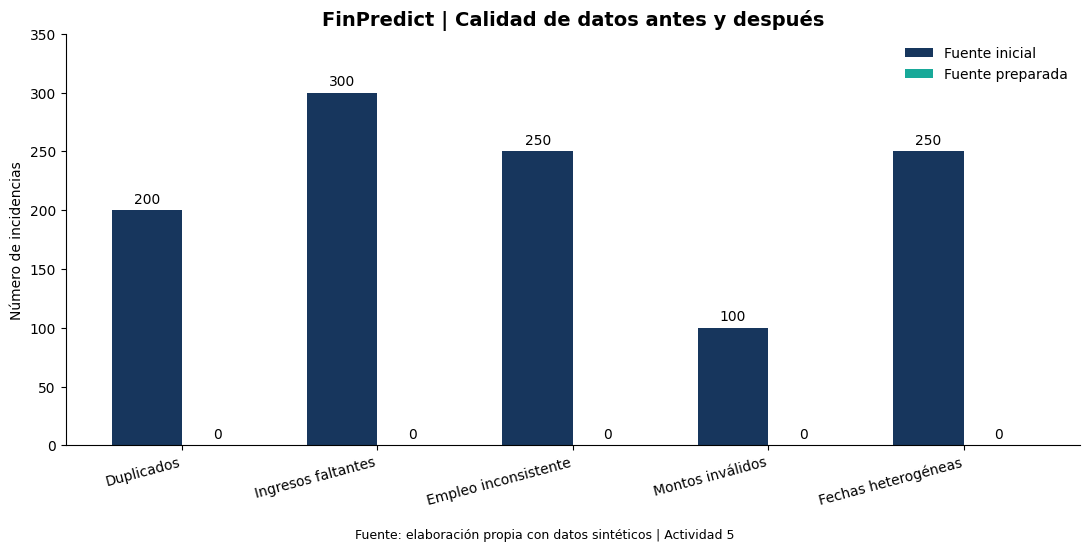

Incidencias iniciales: 1,100
Incidencias restantes: 0
Tasa de resolución: 100.00%


In [24]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 16
# Visualización ejecutiva de calidad de datos
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

# Seleccionar solo las cinco incidencias de calidad
indicadores = [
    "Duplicados por clave",
    "Ingresos faltantes",
    "Empleos inconsistentes",
    "Montos inválidos",
    "Fechas en formato alternativo"
]

comparacion = (
    df_comparativo_calidad
    .set_index("indicador")
    .loc[indicadores, ["antes", "despues"]]
)

etiquetas = [
    "Duplicados",
    "Ingresos faltantes",
    "Empleo inconsistente",
    "Montos inválidos",
    "Fechas heterogéneas"
]

posiciones = np.arange(len(etiquetas))
ancho = 0.36

fig, ax = plt.subplots(figsize=(11, 5.5))

barras_antes = ax.bar(
    posiciones - ancho / 2,
    comparacion["antes"],
    ancho,
    label="Fuente inicial",
    color="#17365D"
)

barras_despues = ax.bar(
    posiciones + ancho / 2,
    comparacion["despues"],
    ancho,
    label="Fuente preparada",
    color="#18A999"
)

ax.bar_label(barras_antes, padding=3)
ax.bar_label(barras_despues, padding=3)

ax.set_xticks(posiciones)
ax.set_xticklabels(etiquetas, rotation=15, ha="right")

ax.set_ylabel("Número de incidencias")
ax.set_title(
    "FinPredict | Calidad de datos antes y después",
    fontsize=14,
    fontweight="bold"
)

ax.set_ylim(0, 350)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)

fig.text(
    0.5, 0.01,
    "Fuente: elaboración propia con datos sintéticos | Actividad 5",
    ha="center",
    fontsize=9
)

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

# Indicador global de resolución
incidencias_iniciales = int(comparacion["antes"].sum())
incidencias_finales = int(comparacion["despues"].sum())

tasa_resolucion = (
    (incidencias_iniciales - incidencias_finales)
    / incidencias_iniciales
    * 100
)

print(f"Incidencias iniciales: {incidencias_iniciales:,}")
print(f"Incidencias restantes: {incidencias_finales:,}")
print(f"Tasa de resolución: {tasa_resolucion:.2f}%")



### 17. Validación de integridad analítica y temporal

Una vez concluida la preparación de datos, se verifica que las transformaciones realizadas no hayan alterado el universo de observaciones, la variable objetivo ni las ventanas temporales.

Este control permite separar dos dimensiones de calidad:

- **Calidad de datos:** completitud, consistencia, unicidad y protección de identificadores.
- **Integridad analítica:** conservación de etiquetas, población elegible y separación temporal entre desarrollo y evaluación final.

La validación se realiza contra la versión analítica original `v0`, preservada como referencia independiente del proceso de limpieza.


In [25]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 17
# Validación de integridad analítica y temporal
# ============================================================

import pandas as pd

# Cargar referencia analítica validada
URL_REFERENCIA = BASE_URL + "finpredict_analitico_v0.parquet"

df_referencia_v0 = pd.read_parquet(URL_REFERENCIA)

CLAVE = ["id_credito", "fecha_corte"]

# Verificar unicidad
assert not df_limpio.duplicated(CLAVE).any()
assert not df_referencia_v0.duplicated(CLAVE).any()

# Comparar únicamente campos que no debieron modificarse
COLUMNAS_CONTROL = [
    "id_credito",
    "fecha_corte",
    "inicio_prediccion",
    "fin_prediccion",
    "uso",
    "incumplimiento_90d"
]

original = (
    df_referencia_v0[COLUMNAS_CONTROL]
    .sort_values(CLAVE)
    .reset_index(drop=True)
)

preparado = (
    df_limpio[COLUMNAS_CONTROL]
    .sort_values(CLAVE)
    .reset_index(drop=True)
)

# Verificar equivalencia exacta
pd.testing.assert_frame_equal(original, preparado)

# Verificar separación temporal
assert (
    df_limpio["inicio_prediccion"]
    > df_limpio["fecha_corte"]
).all()

assert (
    df_limpio["fin_prediccion"]
    >= df_limpio["inicio_prediccion"]
).all()

# Comprobar universo y etiquetas
resumen_integridad = pd.DataFrame({
    "indicador": [
        "Observaciones totales",
        "Contratos distintos",
        "Eventos de incumplimiento",
        "Desarrollo histórico",
        "Evaluación final",
        "Duplicados por clave"
    ],
    "referencia_v0": [
        len(df_referencia_v0),
        df_referencia_v0["id_credito"].nunique(),
        int(df_referencia_v0["incumplimiento_90d"].sum()),
        int(df_referencia_v0["uso"].eq("HISTORICO").sum()),
        int(df_referencia_v0["uso"].eq("EVALUACION_FINAL").sum()),
        int(df_referencia_v0.duplicated(CLAVE).sum())
    ],
    "dataset_preparado": [
        len(df_limpio),
        df_limpio["id_credito"].nunique(),
        int(df_limpio["incumplimiento_90d"].sum()),
        int(df_limpio["uso"].eq("HISTORICO").sum()),
        int(df_limpio["uso"].eq("EVALUACION_FINAL").sum()),
        int(df_limpio.duplicated(CLAVE).sum())
    ]
})

resumen_integridad["coincide"] = (
    resumen_integridad["referencia_v0"]
    == resumen_integridad["dataset_preparado"]
)

assert resumen_integridad["coincide"].all()

print("FINPREDICT | Integridad analítica y temporal")
print("-" * 65)

display(resumen_integridad)

print("-" * 65)
print("Universo, etiquetas y particiones temporales conservados.")


FINPREDICT | Integridad analítica y temporal
-----------------------------------------------------------------


,indicador,referencia_v0,dataset_preparado,coincide
0,Observaciones totales,390661,390661,True
1,Contratos distintos,44913,44913,True
2,Eventos de incumplimiento,23650,23650,True
3,Desarrollo histórico,350520,350520,True
4,Evaluación final,40141,40141,True
5,Duplicados por clave,0,0,True


-----------------------------------------------------------------
Universo, etiquetas y particiones temporales conservados.



### 18. Auditoría de variables y prevención de fuga de información

La calidad de los datos no garantiza por sí misma su idoneidad para entrenar modelos predictivos.

Antes del modelado se realiza un inventario de variables para identificar:

- **Variable objetivo:** resultado futuro que se desea predecir.
- **Identificadores y campos de control:** necesarios para trazabilidad, pero excluidos del entrenamiento.
- **Variables de auditoría:** evidencias del tratamiento de datos y de la simulación.
- **Variables candidatas:** atributos financieros, contractuales y de comportamiento potencialmente disponibles al momento de la predicción.
- **Variables sujetas a revisión temporal:** atributos cuya construcción debe verificarse para descartar información posterior al corte.

La selección definitiva de predictores estará condicionada a su disponibilidad temporal, justificación de negocio y evaluación de riesgos de sesgo.


In [26]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 18
# Inventario de variables y revisión para modelado
# ============================================================

import pandas as pd

# Clasificación inicial de columnas
columnas_objetivo = {"incumplimiento_90d"}

columnas_control = {
    "id_credito",
    "id_ventana",
    "fecha_corte",
    "inicio_prediccion",
    "fin_prediccion",
    "uso"
}

columnas_auditoria = {
    "mora_90_corte",
    "pagos_parciales_3m",
    "regularizaciones_3m",
    "categoria_cobertura_3m",
    "ingreso_faltante_original",
    "metodo_recuperacion_ingreso",
    "monto_invalido_original",
    "metodo_recuperacion_monto"
}

columnas_revision_temporal = {
    "importe_pagado_3m",
    "numero_pagos_3m",
    "importe_exigible_3m",
    "obligaciones_3m",
    "porcentaje_pago_3m",
    "saldo_vencido",
    "dias_atraso"
}

def clasificar_variable(nombre):
    if nombre in columnas_objetivo:
        return "OBJETIVO"
    if nombre in columnas_control:
        return "CONTROL / TRAZABILIDAD"
    if nombre in columnas_auditoria:
        return "AUDITORÍA"
    if nombre in columnas_revision_temporal:
        return "REVISIÓN TEMPORAL"
    return "CANDIDATA A PREDICTOR"

inventario_variables = pd.DataFrame({
    "variable": df_limpio.columns,
    "tipo_dato": [
        str(df_limpio[col].dtype)
        for col in df_limpio.columns
    ],
    "nulos": [
        int(df_limpio[col].isna().sum())
        for col in df_limpio.columns
    ],
    "valores_distintos": [
        int(df_limpio[col].nunique(dropna=True))
        for col in df_limpio.columns
    ],
    "clasificacion_inicial": [
        clasificar_variable(col)
        for col in df_limpio.columns
    ]
})

print("FINPREDICT | Inventario de variables")
print("-" * 65)

display(inventario_variables)

print("\nDistribución por clasificación:")
display(
    inventario_variables["clasificacion_inicial"]
    .value_counts()
    .rename_axis("clasificacion")
    .reset_index(name="variables")
)

print("-" * 65)
print("Inventario generado. No se modificó el dataset.")


FINPREDICT | Inventario de variables
-----------------------------------------------------------------


,variable,tipo_dato,nulos,valores_distintos,clasificacion_inicial
0,id_credito,object,0,44913,CONTROL / TRAZABILIDAD
1,id_ventana,int64,0,18,CONTROL / TRAZABILIDAD
2,fecha_corte,datetime64[ns],0,18,CONTROL / TRAZABILIDAD
3,inicio_prediccion,datetime64[ns],0,18,CONTROL / TRAZABILIDAD
4,fin_prediccion,datetime64[ns],0,18,CONTROL / TRAZABILIDAD
5,uso,object,0,2,CONTROL / TRAZABILIDAD
6,fecha_apertura,datetime64[ns],0,1642,CANDIDATA A PREDICTOR
7,incumplimiento_90d,int64,0,2,OBJETIVO
8,monto_original,float64,0,44912,CANDIDATA A PREDICTOR
9,plazo_meses,int64,0,4,CANDIDATA A PREDICTOR



Distribución por clasificación:


,clasificacion,variables
0,CANDIDATA A PREDICTOR,12
1,AUDITORÍA,8
2,REVISIÓN TEMPORAL,7
3,CONTROL / TRAZABILIDAD,6
4,OBJETIVO,1


-----------------------------------------------------------------
Inventario generado. No se modificó el dataset.


In [27]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 19
# Auditoría de ventanas temporales y variables constantes
# ============================================================

import pandas as pd

# 1. Resumen de las ventanas temporales
ventanas = (
    df_limpio.groupby(
        ["id_ventana", "fecha_corte",
         "inicio_prediccion", "fin_prediccion", "uso"],
        dropna=False
    )
    .agg(
        observaciones=("id_credito", "size"),
        eventos=("incumplimiento_90d", "sum")
    )
    .reset_index()
    .sort_values(["fecha_corte", "uso"])
)

# 2. Validar que la predicción inicia después del corte
ventanas["separacion_correcta"] = (
    ventanas["inicio_prediccion"] > ventanas["fecha_corte"]
)

assert ventanas["separacion_correcta"].all()

# 3. Detectar columnas constantes
constantes = (
    df_limpio.nunique(dropna=False)
    .loc[lambda serie: serie <= 1]
    .index.tolist()
)

# 4. Comprobar fechas del conjunto reservado
evaluacion = df_limpio.loc[
    df_limpio["uso"] == "EVALUACION_FINAL"
]

assert len(evaluacion) == 40_141

# 5. Mostrar resultados
print("FINPREDICT | Auditoría temporal")
print("-" * 65)

print("Ventanas de análisis:")
display(ventanas)

print("\nVariables constantes:")
display(
    pd.DataFrame({
        "variable": constantes,
        "valor_distinto": [
            df_limpio[col].iloc[0]
            for col in constantes
        ]
    })
)

print("\nEvaluación final:")
print("Fecha de corte mínima:", evaluacion["fecha_corte"].min())
print("Fecha de corte máxima:", evaluacion["fecha_corte"].max())
print("Observaciones:", len(evaluacion))

print("-" * 65)
print("Auditoría descriptiva completada.")


FINPREDICT | Auditoría temporal
-----------------------------------------------------------------
Ventanas de análisis:


,id_ventana,fecha_corte,inicio_prediccion,fin_prediccion,uso,observaciones,eventos,separacion_correcta
0,2,2021-06-30,2021-07-01,2021-09-30,HISTORICO,2505,112,True
1,3,2021-09-30,2021-10-01,2021-12-31,HISTORICO,4874,254,True
2,4,2021-12-31,2022-01-01,2022-03-31,HISTORICO,7327,491,True
3,5,2022-03-31,2022-04-01,2022-06-30,HISTORICO,9649,682,True
4,6,2022-06-30,2022-07-01,2022-09-30,HISTORICO,11914,807,True
5,7,2022-09-30,2022-10-01,2022-12-31,HISTORICO,14155,950,True
6,8,2022-12-31,2023-01-01,2023-03-31,HISTORICO,16409,1029,True
7,9,2023-03-31,2023-04-01,2023-06-30,HISTORICO,18608,1208,True
8,10,2023-06-30,2023-07-01,2023-09-30,HISTORICO,20785,1405,True
9,11,2023-09-30,2023-10-01,2023-12-31,HISTORICO,22812,1396,True



Variables constantes:


,variable,valor_distinto
0,obligaciones_3m,3
1,mora_90_corte,0



Evaluación final:
Fecha de corte mínima: 2025-09-30 00:00:00
Fecha de corte máxima: 2025-09-30 00:00:00
Observaciones: 40141
-----------------------------------------------------------------
Auditoría descriptiva completada.



### 19. Selección de variables predictoras

Se define un conjunto inicial de variables para el desarrollo de modelos supervisados.

**Criterios de selección:**
- Disponibilidad de información hasta la fecha de corte.
- Relevancia contractual, financiera o de comportamiento.
- Exclusión de identificadores y campos de auditoría.
- Exclusión de variables constantes.
- Separación de la variable objetivo y las ventanas de evaluación.

Las variables de auditoría se preservan para trazabilidad, pero no se incorporan automáticamente al entrenamiento.

La selección se considera inicial y podrá ajustarse durante la validación de los modelos.


In [28]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 20
# Selección inicial de variables predictoras
# ============================================================

VARIABLE_OBJETIVO = "incumplimiento_90d"

PREDICTORES = [
    "monto_original",
    "plazo_meses",
    "tasa_interes_anual",
    "pago_mensual",
    "ingreso_mensual",
    "antiguedad_meses",
    "saldo_vencido",
    "dias_atraso",
    "relacion_pago_ingreso",
    "saldo_vencido_mensualidades",
    "importe_pagado_3m",
    "numero_pagos_3m",
    "importe_exigible_3m",
    "porcentaje_pago_3m"
]

# Validar disponibilidad de variables
assert set(PREDICTORES).issubset(df_limpio.columns)
assert VARIABLE_OBJETIVO in df_limpio.columns

# Verificar ausencia de nulos
assert not df_limpio[PREDICTORES].isna().any().any()

# Verificar que las variables sean numéricas
assert all(
    pd.api.types.is_numeric_dtype(df_limpio[col])
    for col in PREDICTORES
)

# Excluir variables sin variación
assert all(
    df_limpio[col].nunique() > 1
    for col in PREDICTORES
)

# Resumen
resumen_predictores = pd.DataFrame({
    "variable": PREDICTORES,
    "tipo_dato": [
        str(df_limpio[col].dtype)
        for col in PREDICTORES
    ],
    "valores_distintos": [
        df_limpio[col].nunique()
        for col in PREDICTORES
    ]
})

print("FINPREDICT | Selección inicial de predictores")
print("-" * 65)

display(resumen_predictores)

print(f"\nPredictores seleccionados: {len(PREDICTORES)}")
print(f"Variable objetivo: {VARIABLE_OBJETIVO}")

print("-" * 65)
print("Selección inicial validada.")


FINPREDICT | Selección inicial de predictores
-----------------------------------------------------------------


,variable,tipo_dato,valores_distintos
0,monto_original,float64,44912
1,plazo_meses,int64,4
2,tasa_interes_anual,float64,34298
3,pago_mensual,float64,44721
4,ingreso_mensual,float64,44857
5,antiguedad_meses,int32,54
6,saldo_vencido,float64,175952
7,dias_atraso,int64,90
8,relacion_pago_ingreso,float64,44954
9,saldo_vencido_mensualidades,float64,211698



Predictores seleccionados: 14
Variable objetivo: incumplimiento_90d
-----------------------------------------------------------------
Selección inicial validada.



### 20. Versionamiento del conjunto preparado

Se genera la versión `v1` del dataset FinPredict tras completar los tratamientos de calidad, deduplicación y minimización de identificadores personales.

Se preservan tres conjuntos:

- **Preparado completo:** observaciones válidas y columnas de auditoría.
- **Desarrollo histórico:** datos destinados al entrenamiento y validación temporal.
- **Evaluación final:** periodo reservado que no se utilizará para seleccionar modelos o hiperparámetros.

La versión incluye un manifiesto JSON con metadatos, variables predictoras, controles de integridad y huellas SHA-256.

**Limitación metodológica:** los valores imputados mediante medianas del conjunto histórico requieren tratamiento compatible con los pliegues de validación temporal antes de reportar métricas finales de modelado.


In [29]:

# ============================================================
# FINPREDICT | ACTIVIDAD 5
# NOTEBOOK 02 - CELDA 21
# Versionamiento y respaldo del dataset preparado
# ============================================================

from pathlib import Path
import pandas as pd
import hashlib
import json

# Directorio del proyecto en Google Drive
RUTA_SALIDA = Path(
    "/content/drive/MyDrive/FinPredict-Actividad5/"
    "datos_preparados/v1"
)

RUTA_SALIDA.mkdir(parents=True, exist_ok=True)

# Separación de desarrollo y evaluación final
df_desarrollo_v1 = df_limpio.loc[
    df_limpio["uso"] == "HISTORICO"
].copy()

df_evaluacion_v1 = df_limpio.loc[
    df_limpio["uso"] == "EVALUACION_FINAL"
].copy()

# Controles antes de guardar
assert len(df_limpio) == 390_661
assert len(df_desarrollo_v1) == 350_520
assert len(df_evaluacion_v1) == 40_141

assert len(df_limpio) == (
    len(df_desarrollo_v1) + len(df_evaluacion_v1)
)

assert "nombre_titular" not in df_limpio.columns
assert "rfc_sintetico" not in df_limpio.columns
assert "direccion" not in df_limpio.columns

# Archivos a versionar
archivos = {
    "finpredict_preparado_v1.parquet": df_limpio,
    "finpredict_desarrollo_v1.parquet": df_desarrollo_v1,
    "finpredict_evaluacion_v1.parquet": df_evaluacion_v1
}

metadatos_archivos = {}

for nombre, dataframe in archivos.items():

    ruta = RUTA_SALIDA / nombre

    dataframe.to_parquet(
        ruta,
        index=False,
        engine="pyarrow",
        compression="snappy"
    )

    # Verificar lectura e integridad lógica
    recuperado = pd.read_parquet(ruta)

    pd.testing.assert_frame_equal(
        dataframe.reset_index(drop=True),
        recuperado.reset_index(drop=True)
    )

    # Calcular SHA-256
    sha256 = hashlib.sha256()

    with ruta.open("rb") as archivo:
        for bloque in iter(
            lambda: archivo.read(1024 * 1024),
            b""
        ):
            sha256.update(bloque)

    metadatos_archivos[nombre] = {
        "registros": int(len(dataframe)),
        "columnas": int(dataframe.shape[1]),
        "sha256": sha256.hexdigest()
    }

# Manifiesto reproducible
manifiesto_v1 = {
    "proyecto": "FinPredict",
    "actividad": 5,
    "version": "v1",
    "notebook_origen": "02_preparacion_datos.ipynb",
    "fuente": "finpredict_fuente_calidad.parquet",
    "estado": "Preparado para fase de modelado",
    "variable_objetivo": VARIABLE_OBJETIVO,
    "predictores": PREDICTORES,
    "numero_predictores": len(PREDICTORES),
    "particion": {
        "desarrollo": "HISTORICO",
        "evaluacion_final": "EVALUACION_FINAL"
    },
    "controles_calidad": {
        "duplicados_restantes": 0,
        "ingresos_faltantes": 0,
        "montos_invalidos": 0,
        "identificadores_directos_suprimidos": 3,
        "etiquetas_preservadas": True
    },
    "observacion_metodologica": (
        "La imputacion por mediana realizada en v1 es "
        "preliminar. En validacion temporal deben "
        "ajustarse las transformaciones exclusivamente "
        "con los datos de entrenamiento de cada pliegue."
    ),
    "archivos": metadatos_archivos
}

ruta_manifiesto = RUTA_SALIDA / "manifiesto_v1.json"

with ruta_manifiesto.open("w", encoding="utf-8") as archivo:
    json.dump(
        manifiesto_v1,
        archivo,
        ensure_ascii=False,
        indent=2
    )

# Resumen de salida
print("FINPREDICT | Versionamiento v1")
print("-" * 65)

resumen_versionamiento = pd.DataFrame([
    {
        "archivo": nombre,
        "registros": datos["registros"],
        "columnas": datos["columnas"],
        "tamano_mb": round(
            (RUTA_SALIDA / nombre).stat().st_size / 1024**2,
            2
        )
    }
    for nombre, datos in metadatos_archivos.items()
])

display(resumen_versionamiento)

print(f"\nRuta: {RUTA_SALIDA}")
print(f"Manifiesto: {ruta_manifiesto.name}")

print("-" * 65)
print("Versión v1 respaldada y verificada.")


FINPREDICT | Versionamiento v1
-----------------------------------------------------------------


,archivo,registros,columnas,tamano_mb
0,finpredict_preparado_v1.parquet,390661,34,17.29
1,finpredict_desarrollo_v1.parquet,350520,34,15.60
2,finpredict_evaluacion_v1.parquet,40141,34,3.41



Ruta: /content/drive/MyDrive/FinPredict-Actividad5/datos_preparados/v1
Manifiesto: manifiesto_v1.json
-----------------------------------------------------------------
Versión v1 respaldada y verificada.


In [30]:
from google.colab import drive

print(
    "Google Drive montado:",
    drive._os.path.ismount("/content/drive")
)

Google Drive montado: False


In [32]:

# ============================================================
# FINPREDICT | Respaldo seguro en Google Drive
# ============================================================

from google.colab import drive
from pathlib import Path
import shutil
import hashlib
import os

# 1. Verificar respaldo temporal
origen = Path("/content/finpredict_respaldo_v1")

archivos = [
    "finpredict_preparado_v1.parquet",
    "finpredict_desarrollo_v1.parquet",
    "finpredict_evaluacion_v1.parquet",
    "manifiesto_v1.json"
]

assert all((origen / nombre).is_file() for nombre in archivos), (
    "Faltan archivos en el respaldo temporal."
)

print("Respaldo temporal verificado: 4 archivos.")

# 2. Montar Drive en una ruta diferente
drive.mount("/content/drive_real")

assert os.path.ismount("/content/drive_real"), (
    "No se pudo confirmar el montaje de Google Drive."
)

# 3. Crear directorio en el Drive real
destino = Path(
    "/content/drive_real/MyDrive/"
    "FinPredict-Actividad5/datos_preparados/v1"
)

destino.mkdir(parents=True, exist_ok=True)

# 4. Copiar archivos
for nombre in archivos:
    shutil.copy2(origen / nombre, destino / nombre)

# 5. Validar integridad
def sha256_archivo(ruta):
    sha = hashlib.sha256()
    with open(ruta, "rb") as f:
        for bloque in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            sha.update(bloque)
    return sha.hexdigest()

for nombre in archivos:
    assert sha256_archivo(origen / nombre) == sha256_archivo(
        destino / nombre
    )

print("\nFINPREDICT | Respaldo definitivo")
print("-" * 60)
print("Drive montado:", os.path.ismount("/content/drive_real"))
print("Archivos guardados:", len(archivos))
print("Integridad SHA-256: CORRECTA")
print("Ruta:", destino)
print("-" * 60)
print("Respaldo en Google Drive completado.")


Respaldo temporal verificado: 4 archivos.
Mounted at /content/drive_real

FINPREDICT | Respaldo definitivo
------------------------------------------------------------
Drive montado: True
Archivos guardados: 4
Integridad SHA-256: CORRECTA
Ruta: /content/drive_real/MyDrive/FinPredict-Actividad5/datos_preparados/v1
------------------------------------------------------------
Respaldo en Google Drive completado.
